In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for professional charts
sns.set_theme(style="whitegrid")

# Load the generated datasets
df_assets = pd.read_csv("Assets.csv")
df_events = pd.read_csv("HazardEvents.csv")
df_damage = pd.read_csv("DamageReports.csv")
df_restoration = pd.read_csv("ServiceRestoration.csv")

# Merge them into an analytical flat table for modeling
df_analytical = df_damage.merge(df_assets, on="asset_id", how="left")
df_analytical = df_analytical.merge(df_events, on="event_id", how="left")
df_analytical = df_analytical.merge(df_restoration, on="report_id", how="left")

print("Dataset joined successfully.")
print(f"Total records: {len(df_analytical)}")

# Inspect missingness (Realism check!)
missing_stats = df_analytical.isnull().sum()
print("\nMissing Values per feature:")
print(missing_stats[missing_stats > 0])

Dataset joined successfully.
Total records: 100000

Missing Values per feature:
damage_state                    68661
year_built                      10420
official_vulnerability_score     4940
restoration_id                  97419
crew_assigned_day               97419
time_to_restore_hours           97419
dtype: int64


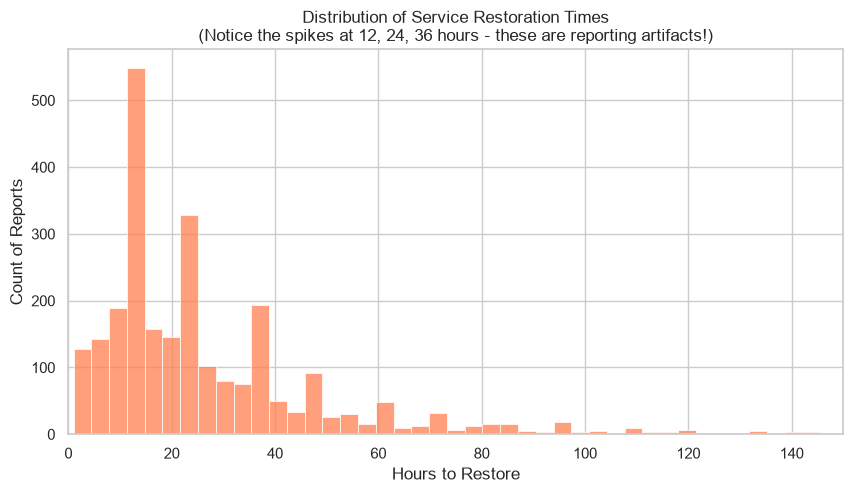

In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(df_analytical['time_to_restore_hours'].dropna(), bins=100, kde=False, color='coral')
plt.title("Distribution of Service Restoration Times\n(Notice the spikes at 12, 24, 36 hours - these are reporting artifacts!)")
plt.xlabel("Hours to Restore")
plt.ylabel("Count of Reports")
plt.xlim(0, 150)
plt.show()

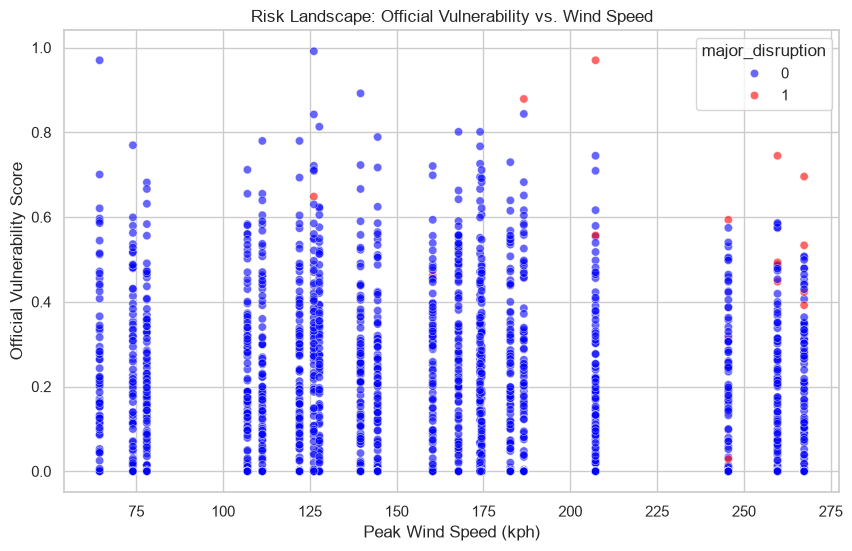

In [6]:
# Create a binary target for Machine Learning: 'Major Disruption' (Severe or Destroyed)
df_analytical['major_disruption'] = df_analytical['damage_state'].isin(['Severe', 'Destroyed']).astype(int)

# Let's plot the relationship between Official Vulnerability, Wind Speed, and Major Disruption
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_analytical.sample(2000, random_state=42), # Sample for plot performance
    x='peak_wind_speed_kph', 
    y='official_vulnerability_score', 
    hue='major_disruption',
    palette={0: 'blue', 1: 'red'},
    alpha=0.6
)
plt.title("Risk Landscape: Official Vulnerability vs. Wind Speed")
plt.xlabel("Peak Wind Speed (kph)")
plt.ylabel("Official Vulnerability Score")
plt.show()

# THE DETECTIVE INSIGHT:
# Notice how there are "Red" (Major Disruption) dots even when Official Vulnerability is low (~0.2) 
# and winds are moderate? This unexplained variance is the statistical "ghost" of our omitted variable!